## AI Reducing Stress Relative to Minutes Using AI

**Graph Type:** Bubble Chart

**Description:** This bubble chart compares how stressed students are, how many minutes they used AI, and whether they feel AI helped them with stress, with each bubble representing a group of students who gave the same answer to "During this week, AI has helped me feel less stressed/anxious about my coursework" (strongly disagree, disagree, neutral, agree, strongly agree). The graph aims to compare the overall stress students may be feeling and seeing how AI might help reduce that stress. In doing so, students might be more inclined to use AI if it helps them both manage schoolwork and reduce stressful situations.

**Hypothesis:** Students who feel that AI helps reduce stress while doing schoolwork are more likely to use AI, and students who are more stressed during the week are more likely to feel that AI helps them. Students who disagree that AI reduces their stress use AI the least.

**Conclusion:** Students who agree that AI helps them feel less stressed use AI more than students who feel neutral about it. The more a student agrees that AI makes their schoolwork less stressful the more minutes they tend to have using AI. The groups who disagree are too small to draw any sizable conclusions from.

## Import

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

survey_df = pd.read_csv("../../data/uncleaned_data.csv")

## Data Cleaning

Here I pulled data from three questions: how much users agree AI decreased stress, their actual stress levels, and the amount of AI used in the last 7 days. I numerized the response on the scale from strong disagree to strong agree from 1-5 to plot it on the graph. I bubbled similar answers together for the question of if they agreed AI decreased stress and plotted it with the x-axis representing the stress levels and y-axis representing the amount of AI used in the last 7 days.

In [ ]:
cols = list(survey_df.columns)
help_col = [c for c in cols if "AI has helped me feel less stressed" in c][0]
agree_scale = {"Strong disagree": 1, "Disagree": 2, "Neutral": 3, "Agree": 4, "Strong agree": 5}
group_names = {1: "Strongly\ndisagree", 2: "Disagree", 3: "Neutral", 4: "Agree", 5: "Strongly\nagree"}


stress_col = [c for c in cols if "past 7 days how much did you experience" in c and "Stress about coursework" in c][0]
minutes_col = [c for c in cols if c.startswith("In the past 7 days, approximately how many minutes")][0]

df = pd.DataFrame({
    "help": survey_df[help_col].astype(str).str.strip().map(agree_scale),
    "stress": pd.to_numeric(survey_df[stress_col], errors="coerce"),
    "minutes": pd.to_numeric(survey_df[minutes_col], errors="coerce"),
}).dropna()

# One bubble per answer group
groups = sorted(df["help"].unique())
stress_avg = [df.loc[df.help == g, "stress"].mean() for g in groups] 
minutes_med = [df.loc[df.help == g, "minutes"].median() for g in groups]
students = [int((df.help == g).sum()) for g in groups]
labels = [group_names[int(g)] for g in groups]
colors = {1: "#d7191c", 2: "#fdae61", 3: "#ffffbf", 4: "#abd9e9", 5: "#2c7bb6"}
bubble_colors = [colors[int(g)] for g in groups]

for lab, n, x_, y_ in zip(labels, students, stress_avg, minutes_med):
    print(f"{lab.replace(chr(10), ' '):<20} n={n:<3} avg stress={x_:.2f}  median minutes={y_:.0f}")

Strongly disagree    n=9   avg stress=3.11  median minutes=0
Disagree             n=5   avg stress=2.60  median minutes=60
Neutral              n=22  avg stress=3.59  median minutes=35
Agree                n=30  avg stress=4.00  median minutes=120
Strongly agree       n=12  avg stress=4.17  median minutes=120


## Creating the Graph

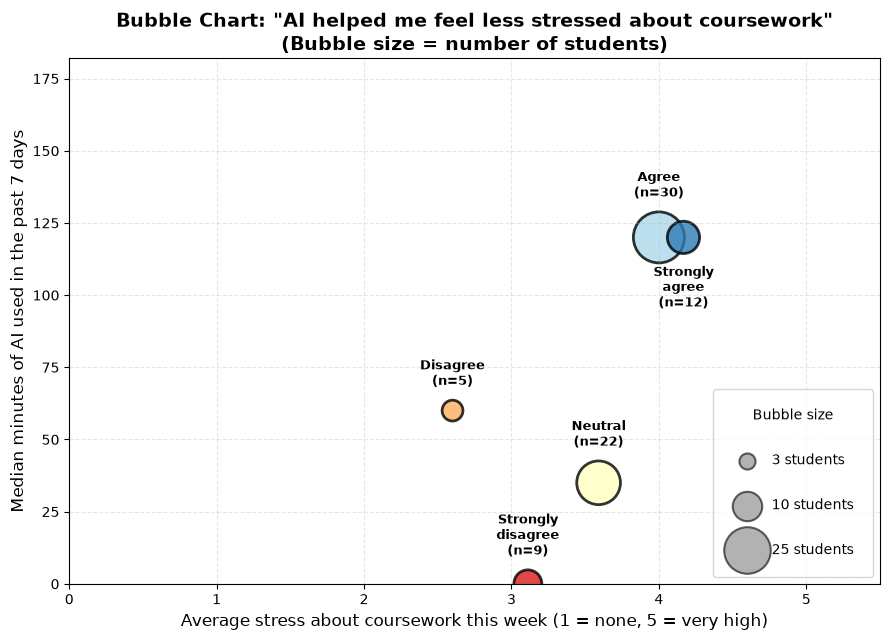

In [ ]:
SCALE = 45

plt.figure(figsize=(9, 6.5))
plt.scatter(stress_avg, minutes_med,
            s=[n * SCALE for n in students],
            c=bubble_colors,
            alpha=0.8,
            edgecolors="black",
            linewidth=2)


below = {5}
for g, lab, n, x_, y_ in zip(groups, labels, students, stress_avg, minutes_med):
    offset = np.sqrt(n * SCALE) / 2 + 8
    if int(g) in below:
        plt.annotate(f"{lab}\n(n={n})", (x_, y_), xytext=(0, -offset), textcoords="offset points",
                     ha="center", va="top", fontweight="bold", fontsize=9)
    else:
        plt.annotate(f"{lab}\n(n={n})", (x_, y_), xytext=(0, offset), textcoords="offset points",
                     ha="center", va="bottom", fontweight="bold", fontsize=9)

plt.xlabel("Average stress about coursework this week (1 = none, 5 = very high)", fontsize=12)
plt.ylabel("Median minutes of AI used in the past 7 days", fontsize=12)
plt.title('Bubble Chart: "AI helped me feel less stressed about coursework"\n'
          "(Bubble size = number of students)", fontsize=14, fontweight="bold")

plt.grid(True, alpha=0.3, linestyle="--")


plt.xlim(0, 5.5)
plt.xticks(range(0, 6))
plt.ylim(0, max(minutes_med) * 1.35 + 20)


legend_sizes = [3, 10, 25]
legend_elements = [plt.scatter([], [], s=v * SCALE, c="gray", alpha=0.6, edgecolors="black",
                               linewidth=1.5, label=f"{v} students") for v in legend_sizes]
plt.legend(handles=legend_elements, title="Bubble size", loc="lower right",
           labelspacing=2.2, borderpad=1.4, frameon=True)

plt.tight_layout()
plt.show()

**Analysis:**
53 students answered both the AI-and-stress question and the minutes question. 33 of them (62%) agreed or strongly agreed that AI helped them feel less stressed, 15 were neutral, and only 5 disagreed or strongly disagreed. The Agree group (23 students) and Strongly Agree group (10 students) each have a median of 120 minutes of AI use, three times the Neutral group's median of 40 minutes (15 students). This directly shows that students who believed that AI reduced workload stress tended to use it more. Although this might not have been the only factor contributing to the increase of AI usage, there is a strong correlation in the visualization that implies that it could have influenced it.

*Note that Median was used over Mean due to a number of outliers in the data set
